# 01 · Análisis exploratorio

**Pregunta:** ¿qué información hay en las curvas granulométricas y en las fotos, y qué problemas habrá que resolver antes de modelar?

1. Las curvas objetivo: indicadores geotécnicos y clasificación.
2. Las fotos: móviles, resolución y escala real.
3. ¿Se ve el tamaño de grano en la foto? Estadísticas simples de imagen frente al D50.
4. Conclusiones para el modelado.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from soilgrain.data import load_labels, load_photo, photo_index
from soilgrain.gradation import gradation_indicators, soil_class

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta categórica validada para 3 clases (daltonismo incluido); el verde va siempre con etiqueta
CLASS_COLOR = {"finos": "#2a78d6", "arena": "#eb6834", "grava": "#1baf7a"}
CLASS_MARKER = {"finos": "o", "arena": "s", "grava": "^"}
CLASSES = list(CLASS_COLOR)
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 1. Curvas granulométricas

In [2]:
labels = load_labels()
sieves = labels.columns.values
print(f"{len(labels)} muestras de entrenamiento · {len(sieves)} tamices de {sieves.min()} a {sieves.max()} mm")
labels.head()

24 muestras de entrenamiento · 11 tamices de 0.002 a 200.0 mm


,0.0020,0.0063,0.0200,0.0630,0.2000,0.6300,2.0000,6.3000,20.0000,63.0000,200.0000
sample_id,,,,,,,,,,,
F827,9.4904,19.3892,47.6257,89.5554,99.8965,99.9896,100.0000,100.0000,100.0000,100.0000,100.0
G190,5.2076,10.2425,23.7537,50.3113,75.8311,85.7233,90.9898,94.8969,98.5814,100.0000,100.0
H030,6.7833,10.9091,19.0599,37.3235,66.8349,96.4965,97.9530,99.5691,100.0000,100.0000,100.0
H037,0.9320,6.4500,16.3216,27.8019,34.6629,46.3652,62.7168,79.0523,89.7830,100.0000,100.0
H038,1.8218,5.1400,10.6113,18.2778,24.6420,35.0767,47.2345,63.3992,81.0851,95.7127,100.0


Cada fila es el **porcentaje acumulado que pasa** por cada tamiz. A partir de ella se calculan los indicadores que usa un geotécnico:

- **D10, D30, D50, D60**: tamaño por el que pasa ese porcentaje (interpolado en escala logarítmica).
- **Cu = D60/D10** (uniformidad) y **Cc = D30²/(D10·D60)** (curvatura). Un suelo está *bien graduado* si Cu es alto y 1 ≤ Cc ≤ 3.
- **Clase** según la fracción dominante (EN ISO 14688): finos < 0,063 mm, arena entre 0,063 y 2 mm, grava entre 2 y 63 mm.

In [3]:
def passing_at(size_mm):
    return [np.interp(np.log10(size_mm), np.log10(sieves), r) for r in labels.values]

fractions = pd.DataFrame({"finos_%": passing_at(0.063)}, index=labels.index)
fractions["arena_%"] = np.array(passing_at(2)) - fractions["finos_%"]
fractions["grava_%"] = 100 - fractions["finos_%"] - fractions["arena_%"]

ind = pd.DataFrame([gradation_indicators(sieves, r) for r in labels.values], index=labels.index)
ind["clase"] = [soil_class(sieves, r) for r in labels.values]
summary = ind.join(fractions)
summary.round(3).sort_values("D50")

,D10,D30,D50,D60,Cu,Cc,clase,finos_%,arena_%,grava_%
sample_id,,,,,,,,,,
F827,0.002,0.010,0.021,0.028,13.225,1.588,finos,89.555,10.445,0.000
H405,NaN,0.008,0.022,0.034,NaN,NaN,finos,75.656,22.798,1.546
H668,0.003,0.014,0.030,0.041,13.128,1.527,finos,73.594,23.449,2.957
H549,0.004,0.013,0.030,0.044,11.572,1.041,finos,69.765,29.987,0.249
H126,0.004,0.017,0.035,0.048,12.314,1.579,finos,68.360,26.487,5.153
H493,0.011,0.032,0.059,0.078,6.944,1.154,finos,51.948,47.262,0.790
G190,0.006,0.026,0.062,0.098,16.386,1.178,finos,50.311,40.678,9.010
H666,0.019,0.037,0.068,0.088,4.589,0.817,arena,46.746,53.043,0.211
H617,0.014,0.049,0.099,0.133,9.334,1.285,arena,34.701,60.068,5.231


In [4]:
summary["clase"].value_counts().reindex(CLASSES).to_frame("muestras")

,muestras
clase,
finos,7
arena,5
grava,12


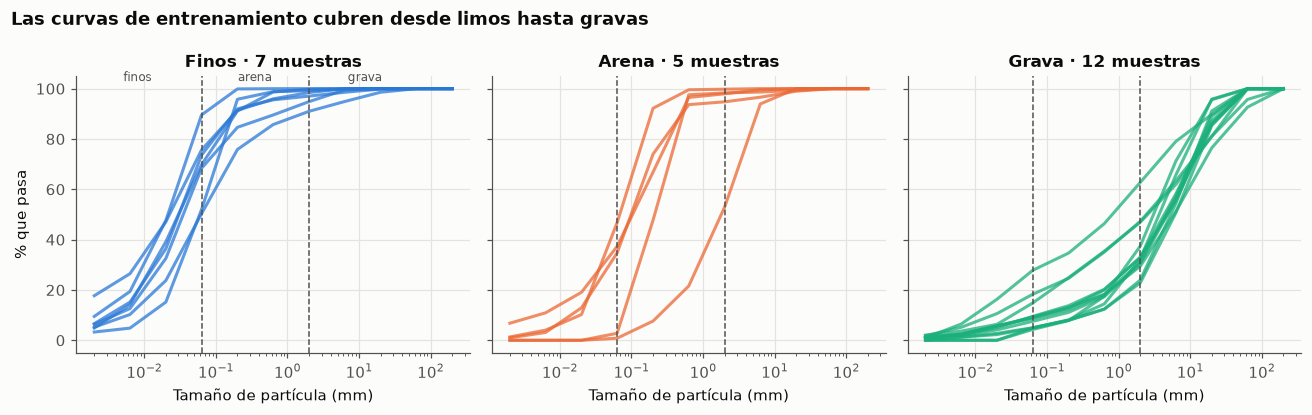

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, cls in zip(axes, CLASSES):
    ids = summary.index[summary["clase"] == cls]
    for sid in ids:
        ax.plot(sieves, labels.loc[sid], color=CLASS_COLOR[cls], alpha=0.75)
    for b in (0.063, 2):
        ax.axvline(b, color=INK_2, lw=1, ls="--")
    ax.set_xscale("log")
    ax.set_title(f"{cls.capitalize()} · {len(ids)} muestras")
    ax.set_xlabel("Tamaño de partícula (mm)")
axes[0].set_ylabel("% que pasa")
for x, txt in [(0.008, "finos"), (0.35, "arena"), (12, "grava")]:
    axes[0].text(x, 103, txt, ha="center", color=INK_2, fontsize=8)
fig.suptitle("Las curvas de entrenamiento cubren desde limos hasta gravas", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "01_curvas_por_clase.png", dpi=150, bbox_inches="tight")

Sin D10 (más del 10 % pasa por el tamiz más fino): ['H405']


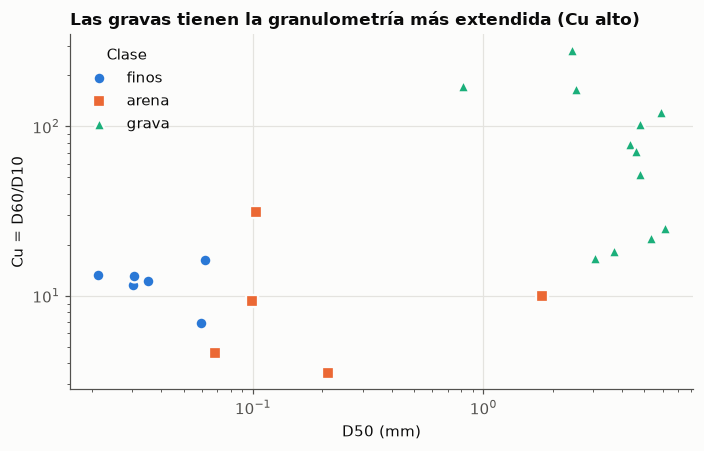

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for cls in CLASSES:
    s = summary[summary["clase"] == cls]
    ax.scatter(s["D50"], s["Cu"], s=60, color=CLASS_COLOR[cls], marker=CLASS_MARKER[cls],
               edgecolor="#fcfcfb", linewidth=1.5, label=cls, zorder=3)
ax.set(xscale="log", yscale="log", xlabel="D50 (mm)", ylabel="Cu = D60/D10")
ax.legend(frameon=False, title="Clase")
ax.set_title("Las gravas tienen la granulometría más extendida (Cu alto)", loc="left")
fig.tight_layout()
fig.savefig(FIG / "02_d50_vs_cu.png", dpi=150, bbox_inches="tight")
missing = summary.index[summary["D10"].isna()].tolist()
print("Sin D10 (más del 10 % pasa por el tamiz más fino):", missing)

**Lectura:**
- El D50 cubre más de **tres órdenes de magnitud** (de ~0,02 mm a ~6 mm). Por eso conviene trabajar en escala logarítmica, igual que el eje de los tamices.
- Las gravas mezclan clastos gruesos con bastante fino, lo que da **Cu > 50** en varias muestras (una granulometría muy extendida). Aun así, cuatro de ellas (H366, H371, H372, H374) tienen **Cc > 3**: la curva es discontinua, porque falta algún tamaño intermedio, y técnicamente serían gravas *mal graduadas*.
- En una muestra (H405) no se puede calcular el D10, porque más del 10 % pasa incluso por 0,002 mm. Habrá que tratar ese caso en la evaluación.

## 2. Las fotos: móviles y escala

In [7]:
photos = photo_index()
(photos.groupby(["split", "phone"])
       .agg(fotos=("path", "size"), muestras=("sample_id", "nunique"),
            resolucion=("width", lambda w: f"{w.iloc[0]}×{photos.loc[w.index[0], 'height']}"),
            ppm_tabla=("ppm_nominal", "first"), ppm_real=("ppm", "mean"), campo_mm=("fov_mm", "mean"))
       .round(2))

fotos  muestras resolucion  ppm_tabla  \
split phone                                                            
test  iPhone 14                   14         3  4032×3024      13.94   
      iPhone 16                   21         7  5712×4284      19.52   
train Motorola Edge               69        22   720×1600      11.49   
      Motorola Edge 60 Fusion      3         1  4096×2304      12.46   
      Samsung A52                 55        22  1599×1200      26.33   

                               ppm_real  campo_mm  
split phone                                        
test  iPhone 14                   13.94    289.20  
      iPhone 16                   19.52    292.55  
train Motorola Edge                4.60    348.07  
      Motorola Edge 60 Fusion     12.46    328.60  
      Samsung A52                  4.55    351.23

**Hallazgo clave:** `ppm_updated.csv` da los píxeles por mm a la resolución **nativa** de cada móvil, pero casi todas las fotos de entrenamiento vienen **reducidas** (1600×720 en lugar de 4000×1800 y 1599×1200 en lugar de 9248×6936). Si se usa el ppm de la tabla sin corregir, la escala sale de 2,5 a 6 veces equivocada.

Lo comprobamos con el campo de visión: tras la corrección, todas las fotos abarcan entre 290 y 350 mm, como cabe esperar de un mismo protocolo de toma.

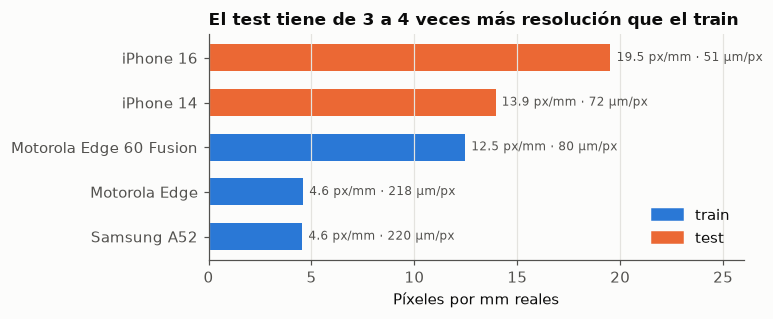

In [8]:
order = photos.groupby("phone")["ppm"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(7, 3))
for i, phone in enumerate(order):
    p = photos[photos["phone"] == phone].iloc[0]
    color = "#2a78d6" if p["split"] == "train" else "#eb6834"
    ax.barh(i, p["ppm"], color=color, height=0.6)
    ax.text(p["ppm"] + 0.3, i, f"{p['ppm']:.1f} px/mm · {1000 / p['ppm']:.0f} µm/px", va="center", fontsize=8, color=INK_2)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Píxeles por mm reales")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 26)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a78d6", label="train"), Patch(color="#eb6834", label="test")], frameon=False, loc="lower right")
ax.set_title("El test tiene de 3 a 4 veces más resolución que el train", loc="left")
fig.tight_layout()
fig.savefig(FIG / "03_resolucion_por_movil.png", dpi=150, bbox_inches="tight")

Consecuencias:
- **Cambio de dominio:** se entrena con Motorola y Samsung y se evalúa solo con iPhone. Para que el modelo vea lo mismo, hay que **reescalar todo a una escala común**. Usaremos 4,5 px/mm, la resolución más baja del train.
- A 4,5 px/mm, un píxel mide **~0,22 mm**: la arena fina, el limo y la arcilla (< 0,2 mm) **no se distinguen grano a grano**. El modelo tendrá que deducir la fracción fina a partir del color y la textura de conjunto, no "contando granos".

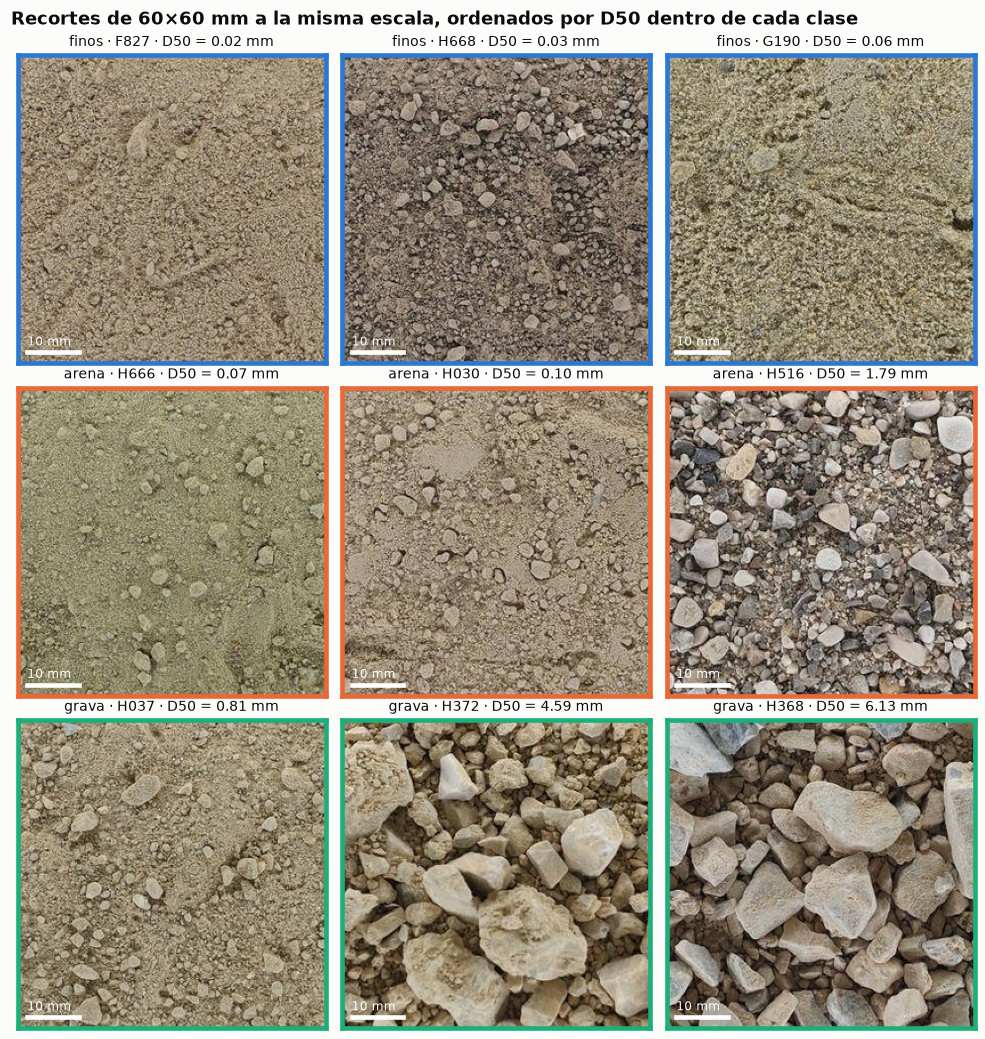

In [9]:
TARGET_PPM = 4.5
CROP_MM = 60

def center_crop(img, size_px):
    h, w = img.shape[:2]
    y, x = (h - size_px) // 2, (w - size_px) // 2
    return img[y:y + size_px, x:x + size_px]

crop_px = int(CROP_MM * TARGET_PPM)
picks = {cls: summary[summary["clase"] == cls].sort_values("D50").index[[0, len(summary[summary["clase"] == cls]) // 2, -1]]
         for cls in CLASSES}

fig, axes = plt.subplots(3, 3, figsize=(9, 9.6))
for row, cls in enumerate(CLASSES):
    for col, sid in enumerate(picks[cls]):
        p = photos[(photos["sample_id"] == sid) & (photos["phone"] == "Samsung A52")]
        p = (p if len(p) else photos[photos["sample_id"] == sid]).iloc[0]
        img = center_crop(load_photo(p["path"], TARGET_PPM, p["ppm"]), crop_px)
        ax = axes[row, col]
        ax.imshow(img)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(True); s.set_color(CLASS_COLOR[cls]); s.set_linewidth(3)
        ax.set_title(f"{cls} · {sid} · D50 = {summary.loc[sid, 'D50']:.2f} mm", fontsize=9, fontweight="normal")
        # Barra de escala de 10 mm
        ax.plot([8, 8 + 10 * TARGET_PPM], [crop_px - 10] * 2, color="white", lw=3)
        ax.text(8, crop_px - 16, "10 mm", color="white", fontsize=8)
fig.suptitle(f"Recortes de {CROP_MM}×{CROP_MM} mm a la misma escala, ordenados por D50 dentro de cada clase",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "04_ejemplos_por_clase.png", dpi=150, bbox_inches="tight")

**Lectura:** la foto no siempre cuenta lo mismo que el laboratorio.
- **H668** (finos, D50 = 0,03 mm) *parece* una gravilla: son **terrones** de suelo fino que se deshacen al lavar la muestra en el tamizado.
- **H037** (grava por clasificación, D50 = 0,81 mm) parece tierra fina: los clastos gruesos están casi enterrados en la matriz.
- **H516** (arena, D50 = 1,8 mm) está justo en el límite con la grava y visualmente ya es una gravilla.

Es decir, el modelo verá la **superficie** de la muestra y no la muestra tamizada. Esto es una fuente de error irreducible que conviene explicar en el README.

## 3. ¿Se ve el tamaño de grano en estadísticas simples de la imagen?

Para cada foto (reescalada a 4,5 px/mm, con un recorte central de 150×150 mm) calculo:
- **brillo**: luminancia media;
- **contraste**: desviación típica de la luminancia;
- **saturación**: saturación media del color;
- **bordes**: magnitud media del gradiente, un indicador de cuántas fronteras entre granos hay;
- **textura gruesa**: fracción de la varianza que sobrevive a un suavizado de 4 mm, que mide cuánta variación hay a la escala de grano grueso.

Promedio por muestra y comparo con log(D50) mediante la **correlación de Spearman**, que solo mide el orden y es robusta con 24 puntos.

In [10]:
from PIL import Image, ImageFilter

def image_stats(img):
    lum = img @ np.array([0.299, 0.587, 0.114]) / 255
    mx, mn = img.max(axis=2) / 255, img.min(axis=2) / 255
    gy, gx = np.gradient(lum)
    smooth = np.asarray(Image.fromarray((lum * 255).astype(np.uint8))
                        .filter(ImageFilter.GaussianBlur(radius=4 * TARGET_PPM)), dtype=float) / 255
    return {
        "brillo": lum.mean(),
        "contraste": lum.std(),
        "saturacion": np.where(mx > 0, (mx - mn) / np.maximum(mx, 1e-6), 0).mean(),
        "bordes": np.hypot(gx, gy).mean(),
        "textura_gruesa": smooth.var() / lum.var(),
    }

stats = pd.DataFrame([
    {**image_stats(center_crop(load_photo(p.path, TARGET_PPM, p.ppm), int(150 * TARGET_PPM))),
     "sample_id": p.sample_id, "phone": p.phone, "split": p.split}
    for p in photos.itertuples()
])
STATS = ["brillo", "contraste", "saturacion", "bordes", "textura_gruesa"]
stats.groupby(["split", "phone"])[STATS].mean().round(3)

brillo  contraste  saturacion  bordes  \
split phone                                                            
test  iPhone 14                 0.601      0.202       0.070   0.095   
      iPhone 16                 0.632      0.125       0.061   0.097   
train Motorola Edge             0.517      0.185       0.149   0.116   
      Motorola Edge 60 Fusion   0.595      0.190       0.299   0.104   
      Samsung A52               0.550      0.152       0.239   0.087   

                               textura_gruesa  
split phone                                    
test  iPhone 14                         0.167  
      iPhone 16                         0.077  
train Motorola Edge                     0.072  
      Motorola Edge 60 Fusion           0.068  
      Samsung A52                       0.121

In [11]:
train_stats = stats[stats["split"] == "train"].groupby("sample_id")[STATS].mean().join(summary[["D50", "clase"]])
train_stats["log_D50"] = np.log10(train_stats["D50"])
rho = train_stats[STATS].corrwith(train_stats["log_D50"], method="spearman").sort_values(key=abs, ascending=False)
rho.to_frame("Spearman vs log D50").round(2)

,Spearman vs log D50
bordes,-0.69
contraste,0.67
textura_gruesa,0.35
brillo,-0.26
saturacion,-0.18


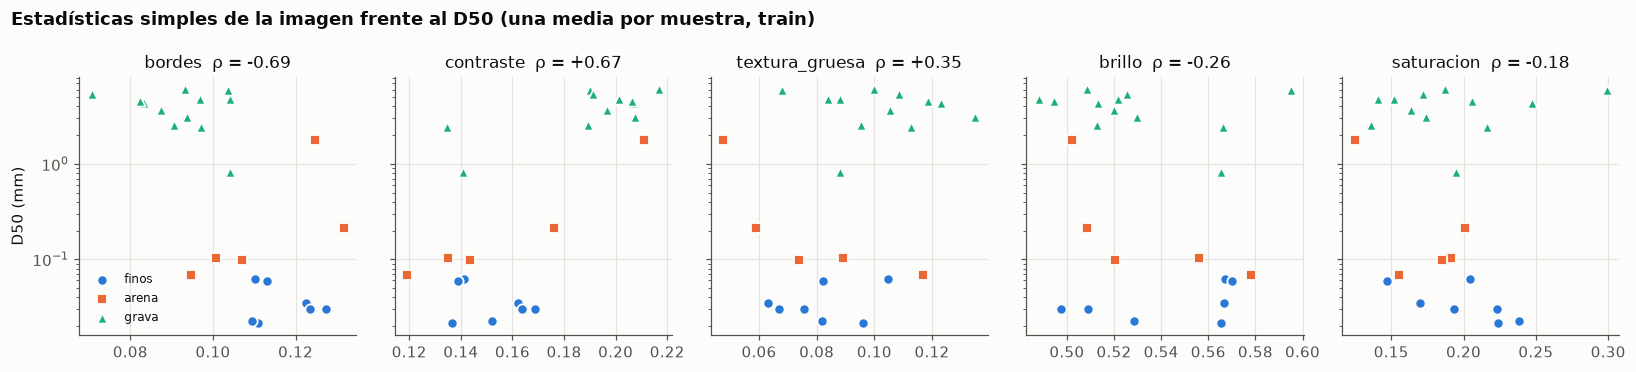

In [12]:
fig, axes = plt.subplots(1, len(STATS), figsize=(15, 3.4), sharey=True)
for ax, col in zip(axes, rho.index):
    for cls in CLASSES:
        s = train_stats[train_stats["clase"] == cls]
        ax.scatter(s[col], s["D50"], s=45, color=CLASS_COLOR[cls], marker=CLASS_MARKER[cls],
                   edgecolor="#fcfcfb", linewidth=1.2, label=cls, zorder=3)
    ax.set_title(f"{col}  ρ = {rho[col]:+.2f}", fontweight="normal")
axes[0].set_yscale("log"); axes[0].set_ylabel("D50 (mm)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Estadísticas simples de la imagen frente al D50 (una media por muestra, train)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "05_estadisticas_vs_d50.png", dpi=150, bbox_inches="tight")

**Lectura:**
- **Contraste (ρ ≈ +0,67):** los clastos gruesos proyectan sombras, así que hay más variación de luz.
- **Bordes (ρ ≈ −0,69):** el signo es contraintuitivo. A 0,22 mm por píxel, la superficie de un suelo fino se ve como una textura granulosa con muchos bordes pequeños, mientras que el interior de un clasto grande es liso.
- Con solo dos variables ya se separan bastante **las gravas del resto**. Distinguir entre finos y arena es más difícil, y ahí el color y el brillo no ayudan de forma consistente.
- Son 24 puntos: las correlaciones dan una orientación, no una prueba.

### Sesgo de cámara: misma muestra, dos móviles

21 muestras se fotografiaron con el Motorola **y** con el Samsung. Esto permite separar el efecto del suelo del efecto de la cámara: si los puntos se alejan de la diagonal, la cámara cambia la estadística aunque el suelo sea el mismo.

,Samsung − Motorola (media)
brillo,0.032
contraste,-0.029
saturacion,0.090
bordes,-0.031
textura_gruesa,0.052


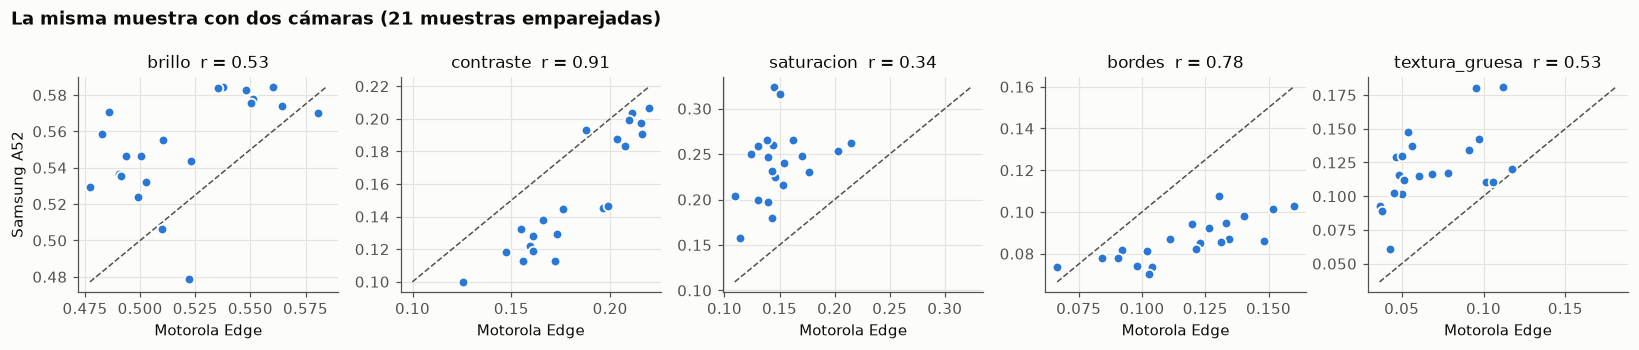

In [13]:
paired = (stats[stats["phone"].isin(["Motorola Edge", "Samsung A52"])]
          .groupby(["sample_id", "phone"])[STATS].mean().unstack("phone").dropna())
fig, axes = plt.subplots(1, len(STATS), figsize=(15, 3.2))
for ax, col in zip(axes, STATS):
    x, y = paired[(col, "Motorola Edge")], paired[(col, "Samsung A52")]
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], color=INK_2, lw=1, ls="--")
    ax.scatter(x, y, s=40, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
    r = np.corrcoef(x, y)[0, 1]
    ax.set_title(f"{col}  r = {r:.2f}", fontweight="normal")
    ax.set_xlabel("Motorola Edge")
axes[0].set_ylabel("Samsung A52")
fig.suptitle(f"La misma muestra con dos cámaras ({len(paired)} muestras emparejadas)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "06_sesgo_camara.png", dpi=150, bbox_inches="tight")
(paired.xs("Samsung A52", axis=1, level="phone") - paired.xs("Motorola Edge", axis=1, level="phone")).mean().round(3).to_frame("Samsung − Motorola (media)")

## 4. Conclusiones para el modelado

In [14]:
print(f"Muestras de entrenamiento: {len(labels)} ({summary['clase'].value_counts().to_dict()})")
print(f"Fotos por muestra: {photos[photos.split == 'train'].groupby('sample_id').size().median():.0f} (mediana)")
print(f"Resolución común: {TARGET_PPM} px/mm = {1000 / TARGET_PPM:.0f} µm por píxel")
print("Correlaciones de Spearman con log D50:", rho.round(2).to_dict())

Muestras de entrenamiento: 24 ({'grava': 12, 'finos': 7, 'arena': 5})
Fotos por muestra: 5 (mediana)
Resolución común: 4.5 px/mm = 222 µm por píxel
Correlaciones de Spearman con log D50: {'bordes': -0.69, 'contraste': 0.67, 'textura_gruesa': 0.35, 'brillo': -0.26, 'saturacion': -0.18}


1. **Hay muy pocos datos (24 muestras).** La validación será *leave-one-sample-out*, agrupando todas las fotos de una muestra para que no aparezca a la vez en train y validación. Una CNN afinada de extremo a extremo sobreajustaría. Lo razonable es extraer muchos recortes por foto, sacar features (de textura o de una CNN congelada) y entrenar un modelo sencillo encima.
2. **La escala tiene que ser física.** Todas las fotos se reescalan a 4,5 px/mm antes de cualquier feature. Sin esto, el modelo aprendería "qué móvil es" en vez de "qué tamaño tiene el grano".
3. **Hay cambio de dominio de cámara.** El test es todo iPhone. En la misma muestra, el Samsung da sistemáticamente **menos contraste y bordes y más saturación** que el Motorola: el orden entre muestras se mantiene (r = 0,91 en contraste), pero el nivel se desplaza. Las features de color habrá que normalizarlas o usarlas con cuidado.
4. **La fracción fina no se resuelve.** Por debajo de ~0,2 mm no hay detalle visible. Es de esperar que el error sea mayor en la parte fina de la curva y en los suelos finos; se comprobará en el análisis de errores.
5. **Hay que predecir en escala logarítmica y con salida monótona.** El D50 abarca tres órdenes de magnitud, y la curva predicha debe ser acumulada y no decreciente.